In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd

from src.data import load_data, time_split, FEATURES
from src.metrices import evaluate

df = load_data()
train, val, test = time_split(df)

X_train = train[FEATURES]
y_train = train["Class"]

X_val = val[FEATURES]
y_val = val["Class"]

In [12]:

import time

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier

# Class imbalance in the training data
positive = int(y_train.sum())
negative = len(y_train) - positive

print("Frauds in training:", positive)
print("Legitimate transactions:", negative)

results = {}
models = {}

# 1. Logistic Regression
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

# 2. Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
# 3. XGBoost
xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=negative / positive,
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)
# 4. DECISION TREE
dt = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=6,
    min_samples_leaf=10,
    random_state=42
)

# Train supervised models and get fraud scores
supervised_models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf,
    "XGBoost": xgb
}
models = {}
scores = {}
results = {}

for name, model in supervised_models.items():
    start = time.time()

    model.fit(X_train, y_train)

    # Fraud probability for each validation transaction
    scores[name] = model.predict_proba(X_val)[:, 1]

    models[name] = model
    results[name] = evaluate(y_val, scores[name])

    print(f"{name} trained in {time.time() - start:.1f} seconds")

# Compare results in one table
comparison = pd.DataFrame(results).T
comparison = comparison.round(3)
comparison.sort_values("P@0.5%", ascending=False)



Frauds in training: 360
Legitimate transactions: 170524
Logistic Regression trained in 1.2 seconds
Decision Tree trained in 7.1 seconds
Random Forest trained in 37.9 seconds
XGBoost trained in 4.2 seconds


,PR_AUC,P@0.1%,R@0.1%,P@0.5%,R@0.5%,P@1.0%,R@1.0%
XGBoost,0.785,0.786,0.772,0.173,0.860,0.086,0.860
Logistic Regression,0.757,0.696,0.684,0.165,0.825,0.086,0.860
Random Forest,0.766,0.768,0.754,0.162,0.807,0.084,0.842
Decision Tree,0.471,0.661,0.649,0.155,0.772,0.077,0.772


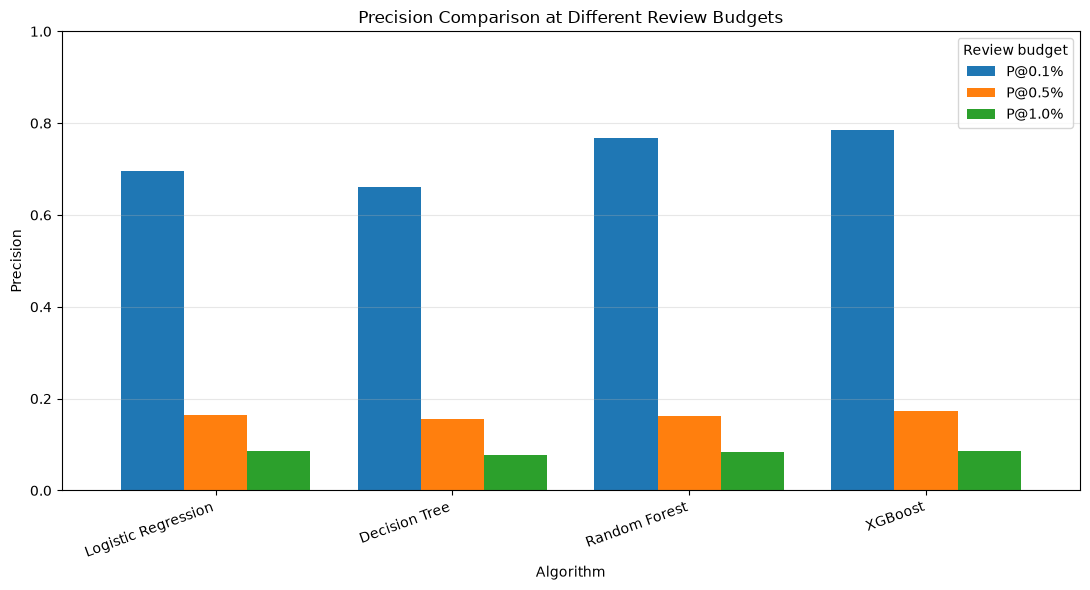

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
metric_cols = ["P@0.1%", "P@0.5%", "P@1.0%"]

comparison[metric_cols].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Precision Comparison at Different Review Budgets")
plt.xlabel("Algorithm")
plt.ylabel("Precision")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Review budget")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

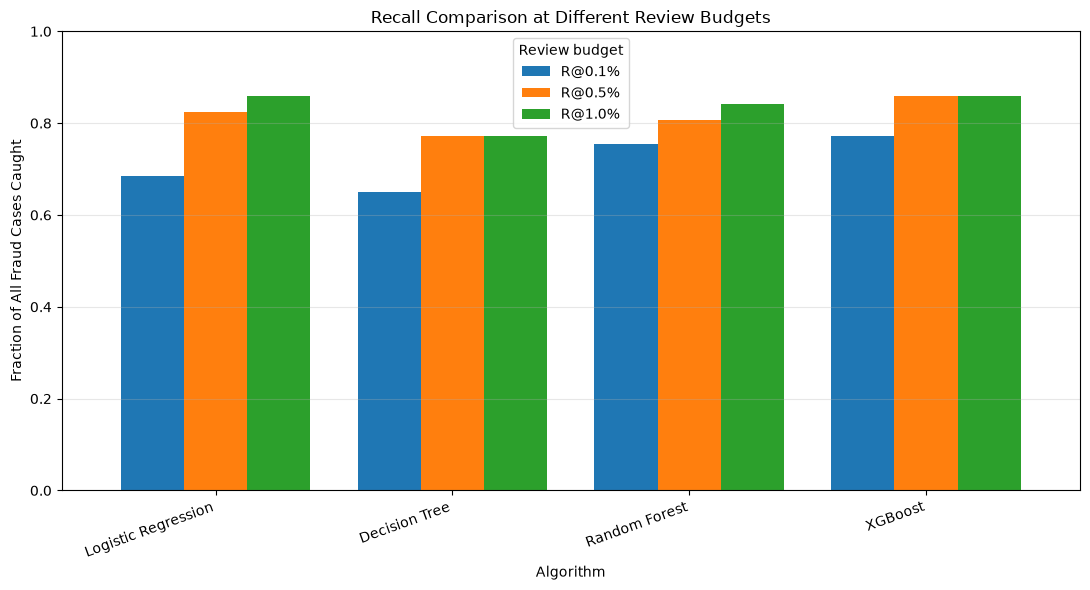

In [14]:
metric_cols = ["R@0.1%", "R@0.5%", "R@1.0%"]

comparison[metric_cols].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Recall Comparison at Different Review Budgets")
plt.xlabel("Algorithm")
plt.ylabel("Fraction of All Fraud Cases Caught")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Review budget")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

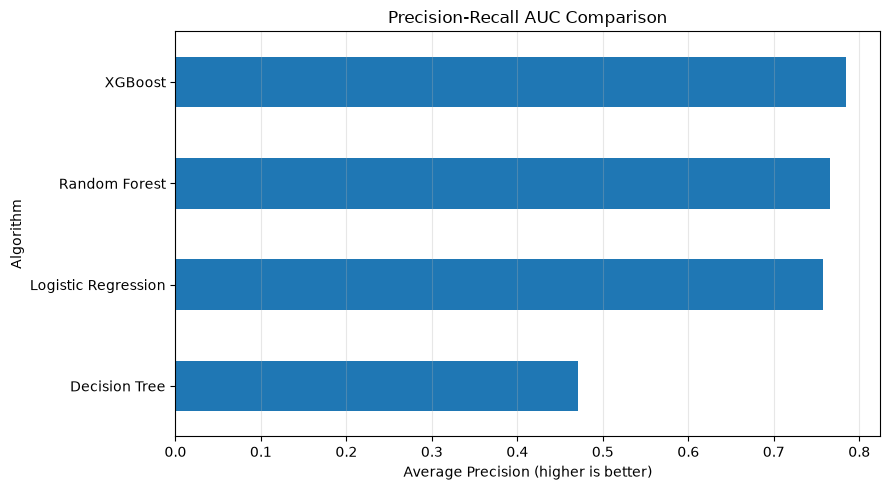

In [15]:
comparison["PR_AUC"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Precision-Recall AUC Comparison")
plt.xlabel("Average Precision (higher is better)")
plt.ylabel("Algorithm")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

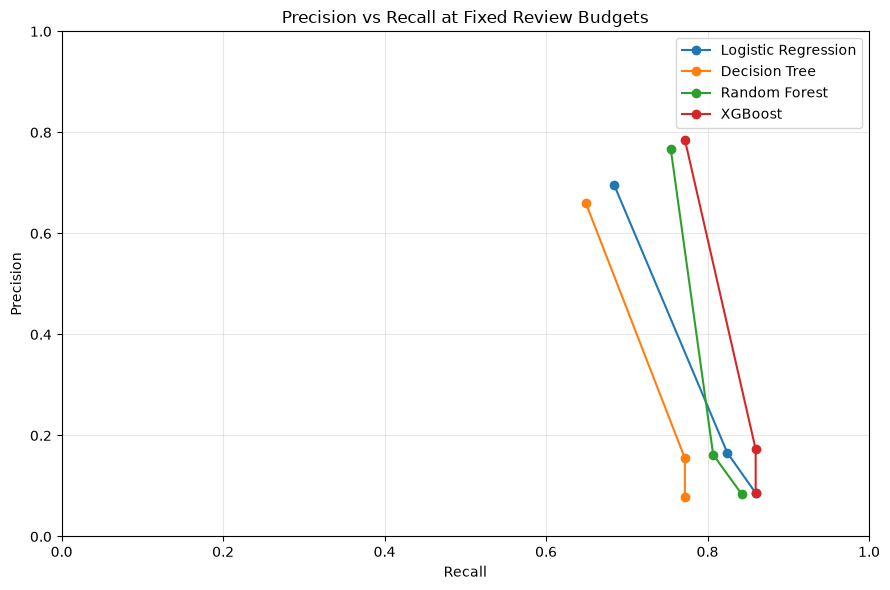

In [16]:
plt.figure(figsize=(9, 6))

for name in scores:
    precision_values = []
    recall_values = []

    for budget in [0.001, 0.005, 0.01]:
        metric = evaluate(
            y_val,
            scores[name],
            budgets=(budget,)
        )

        precision_values.append(metric[f"P@{budget*100:.1f}%"])
        recall_values.append(metric[f"R@{budget*100:.1f}%"])

    plt.plot(
        recall_values,
        precision_values,
        marker="o",
        label=name
    )

plt.title("Precision vs Recall at Fixed Review Budgets")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

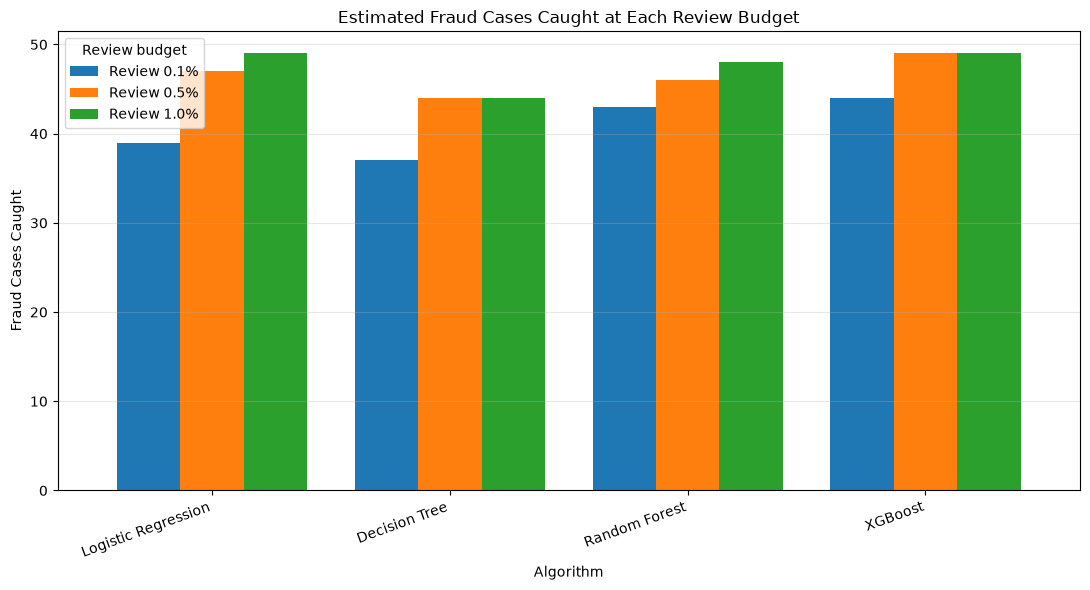

In [17]:
frauds_in_validation = int(y_val.sum())

recall_cols = ["R@0.1%", "R@0.5%", "R@1.0%"]

frauds_caught = comparison[recall_cols] * frauds_in_validation

frauds_caught.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Estimated Fraud Cases Caught at Each Review Budget")
plt.xlabel("Algorithm")
plt.ylabel("Fraud Cases Caught")
plt.xticks(rotation=20, ha="right")
plt.legend(
    ["Review 0.1%", "Review 0.5%", "Review 1.0%"],
    title="Review budget"
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
import os

os.makedirs("../reports", exist_ok=True)

comparison.to_csv(
    "../reports/baseline_model_comparison.csv"
)

print("Comparison table saved successfully!")

Comparison table saved successfully!
